# Notebook 07 - Synthetic Signal Analysis

This notebook analyzes invented values from anonymous signal channels. Results are illustrative and are not sourced from an organization or operating asset.

## Analysis step 2

Import model, statistics, and plotting tools and configure paths to the saved supervised and anomaly outputs.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

HERE = Path.cwd().resolve()
ROOT = None
for candidate in [HERE, *HERE.parents]:
    if (candidate / 'data' / 'processed' / 'features_labels.csv').is_file():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError('Could not find data/processed/features_labels.csv. Run notebooks 04-06 first.')

PROCESSED = ROOT / 'data' / 'processed'
INTERIM = ROOT / 'data' / 'interim'
TABLE_DIR = ROOT / 'reports' / 'tables'
FIG_DIR = ROOT / 'reports' / 'figures'
MODEL_DIR = ROOT / 'models'
for d in (TABLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Settings copied from notebooks 05 and 06 so the rebuilt streams match the saved ones.
RANDOM_STATE = 42
BLOCK_DAYS = 14
GAP_DAYS = 7
MIN_POS_TRAIN = 3
THRESHOLD = 0.5
SUSTAIN_K = 3

FIT_FRACTION = 0.70
ALARM_QUANTILES = [0.95, 0.975, 0.99]
SUSTAIN_WINDOW = 7
SUSTAIN_COUNT = 5

print('Project path:', ROOT)
print('Tables:', TABLE_DIR)
print('Models:', MODEL_DIR)


Project path: D:\ML_NTI\Predictive Maintanance\predictive-maintenance
Tables: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables
Models: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\models


## Analysis step 3

Load the label configuration and evaluation results from notebooks 05 and 06. The event date and horizon define the common reference used for comparing approaches.

In [2]:
with open(PROCESSED / 'label_config.json') as f:
    cfg = json.load(f)
FAILURE_DATE = pd.Timestamp(cfg['failure_date_used'])
FAILURE_PROVISIONAL = cfg.get('failure_date_provisional', True)
MAIN_H = cfg['main_horizon']
HORIZONS = cfg['horizons']
CORE = cfg['core_sensors']

sup_summary = pd.read_csv(TABLE_DIR / '05_supervised_summary.csv', index_col=0)
sup_timing = pd.read_csv(TABLE_DIR / '05_supervised_event_timing.csv', index_col=0)
sup_grid = pd.read_csv(TABLE_DIR / '05_supervised_grid.csv')
sup_horizon = pd.read_csv(TABLE_DIR / '05_supervised_horizon_sensitivity.csv', index_col=0)
sup_gap = pd.read_csv(TABLE_DIR / '05_supervised_gap_sensitivity.csv', index_col=0)
anom_cal = pd.read_csv(TABLE_DIR / '06_anomaly_calibration_summary.csv')
anom_timing = pd.read_csv(TABLE_DIR / '06_anomaly_event_timing.csv')

table = pd.read_csv(PROCESSED / 'features_labels.csv', index_col=0, parse_dates=True)
feature_list = pd.read_csv(PROCESSED / 'feature_list.csv')
FEATURES = [c for c in feature_list['feature'] if c in table.columns]
SCORES = [c for c in ['health_abs7', 'health_max7', 'mahal7'] if c in table.columns]
FEATURES = [c for c in FEATURES if c not in SCORES] + SCORES

print('failure date used:', FAILURE_DATE.date(), '(provisional)' if FAILURE_PROVISIONAL else '(confirmed)')
print('supervised models:', len(sup_timing), '| anomaly rows:', len(anom_timing))
print('features:', len(FEATURES))

print('\nSupervised summary (notebook 05):')
display(sup_summary.round(3))

print('\nAnomaly event timing (notebook 06):')
display(anom_timing)


failure date used: 2033-12-31 (provisional)
supervised models: 2 | anomaly rows: 9
features: 87

Supervised summary (notebook 05):


,scored_rows,scored_pos,total_pos,prevalence,PR_AUC,ROC_AUC
model,,,,,,
Logistic regression (C=0.1),17,17,31,1.000,NaN,NaN
Decision tree (depth 3),17,17,31,1.000,NaN,NaN
Baseline: raw mahal7 (no training),657,31,31,0.047,0.436,0.971



Anomaly event timing (notebook 06):


,model,calibration_quantile,first_sustained_alarm,lead_days_to_configured_date,alarm_episodes_before_horizon,alarm_episodes_inside_horizon,sustained_alarm_days_before_horizon,sustained_alarm_days_inside_horizon,evaluation_start_after_calibration,configured_event_date_provisional
0,Ledoit-Wolf distance,0.950,2033-01-05,360,4,0,293,31,2033-01-01,True
1,Ledoit-Wolf distance,0.975,2033-01-05,360,4,0,293,31,2033-01-01,True
2,Ledoit-Wolf distance,0.990,2033-01-05,360,4,0,293,31,2033-01-01,True
3,Isolation Forest,0.950,2033-01-11,354,16,1,107,29,2033-01-01,True
4,Isolation Forest,0.975,2033-06-16,198,7,2,37,22,2033-01-01,True
5,Isolation Forest,0.990,2033-06-16,198,5,1,11,20,2033-01-01,True
6,PCA reconstruction error,0.950,2033-01-05,360,4,0,293,31,2033-01-01,True
7,PCA reconstruction error,0.975,2033-01-05,360,4,0,293,31,2033-01-01,True
8,PCA reconstruction error,0.990,2033-01-05,360,4,0,293,31,2033-01-01,True


## Analysis step 4

Build a side-by-side timing summary for supervised models and anomaly detectors. The table aligns alarm settings, first sustained alerts, and lead-time measures.

In [3]:
sup_rows = pd.DataFrame({
    'approach': 'supervised (05)',
    'model': sup_timing.index.values,
    'alarm_setting': f'P >= {THRESHOLD} for {SUSTAIN_K} days',
    'first_sustained_alarm': sup_timing['first_sustained_alarm'].values,
    'lead_days': sup_timing['lead_days_to_failure_date'].values,
    'alarm_episodes_before_horizon': sup_timing['alarm_episodes_before_horizon'].values,
    'alarm_episodes_inside_horizon': sup_timing['alarm_episodes_inside_horizon'].values,
    'alarm_days': sup_timing['alarm_days_inside_horizon'].values,
    'false_alarm_days_per_month': sup_timing['false_alarm_days_per_month'].values,
    'false_alarm_days_per_month_raw': sup_timing['false_alarm_days_per_month'].values,
    'calibration_sustained_episodes': np.nan,
    'calibration_sustained_days': np.nan,
    'sustained_alarm_share_2033': np.nan,
})

# Anomaly false-alarm rate from 06's held-out healthy calibration block:
# - false_alarm_days_per_month          sustained (7-day window, 5 days) alarms per month
# - false_alarm_days_per_month_raw      raw threshold exceedance days per month
# - calibration_sustained_episodes      sustained alarm runs in the healthy block
cal = anom_cal.set_index(['model', 'calibration_quantile'])
anom_rows = pd.DataFrame({
    'approach': 'anomaly (06)',
    'model': anom_timing['model'].values,
    'alarm_setting': 'quantile ' + anom_timing['calibration_quantile'].astype(str).values,
    'first_sustained_alarm': anom_timing['first_sustained_alarm'].values,
    'lead_days': anom_timing['lead_days_to_configured_date'].values,
    'alarm_episodes_before_horizon': anom_timing['alarm_episodes_before_horizon'].values,
    'alarm_episodes_inside_horizon': anom_timing['alarm_episodes_inside_horizon'].values,
    'alarm_days': anom_timing['sustained_alarm_days_inside_horizon'].values,
    'false_alarm_days_per_month': [
        cal.loc[(m, q), 'calibration_sustained_days'] / cal.loc[(m, q), 'eligible_calibration_days'] * 30.4
        for m, q in zip(anom_timing['model'], anom_timing['calibration_quantile'])
    ],
    'false_alarm_days_per_month_raw': [
        cal.loc[(m, q), 'calibration_exceedance_days'] / cal.loc[(m, q), 'eligible_calibration_days'] * 30.4
        for m, q in zip(anom_timing['model'], anom_timing['calibration_quantile'])
    ],
    'calibration_sustained_episodes': [
        int(cal.loc[(m, q), 'calibration_alarm_starts'])
        for m, q in zip(anom_timing['model'], anom_timing['calibration_quantile'])
    ],
    'calibration_sustained_days': [
        int(cal.loc[(m, q), 'calibration_sustained_days'])
        for m, q in zip(anom_timing['model'], anom_timing['calibration_quantile'])
    ],
    'sustained_alarm_share_2033': [
        cal.loc[(m, q), '2033_sustained_days'] / max(cal.loc[(m, q), 'eligible_2033_days'], 1)
        for m, q in zip(anom_timing['model'], anom_timing['calibration_quantile'])
    ],
})

leaderboard = pd.concat([sup_rows, anom_rows], ignore_index=True)
leaderboard['failure_date_provisional'] = FAILURE_PROVISIONAL
# a detector that alarms on most eligible days is "continuous"; its long lead is meaningless
leaderboard['continuous_alarm'] = leaderboard['sustained_alarm_share_2033'].fillna(0) > 0.5
# rank together on detection, false alarms and lead time - never on lead alone
leaderboard = leaderboard.sort_values(
    ['continuous_alarm', 'false_alarm_days_per_month', 'lead_days'],
    ascending=[True, True, False], na_position='last').reset_index(drop=True)

display(leaderboard.round(2))
leaderboard.to_csv(TABLE_DIR / '07_comparison_leaderboard.csv', index=False)
print('saved:', TABLE_DIR / '07_comparison_leaderboard.csv')

,approach,model,alarm_setting,first_sustained_alarm,lead_days,alarm_episodes_before_horizon,alarm_episodes_inside_horizon,alarm_days,false_alarm_days_per_month,false_alarm_days_per_month_raw,calibration_sustained_episodes,calibration_sustained_days,sustained_alarm_share_2033,failure_date_provisional,continuous_alarm
0,anomaly (06),Isolation Forest,quantile 0.95,2033-01-11,354,16,1,29,0.0,1.66,0.0,0.0,0.40,True,False
1,anomaly (06),Isolation Forest,quantile 0.975,2033-06-16,198,7,2,22,0.0,0.83,0.0,0.0,0.17,True,False
2,anomaly (06),Isolation Forest,quantile 0.99,2033-06-16,198,5,1,20,0.0,0.55,0.0,0.0,0.09,True,False
3,supervised (05),Logistic regression (C=0.1),P >= 0.5 for 3 days,2033-12-17,14,0,1,15,NaN,NaN,NaN,NaN,NaN,True,False
4,supervised (05),Decision tree (depth 3),P >= 0.5 for 3 days,2033-12-17,14,0,1,5,NaN,NaN,NaN,NaN,NaN,True,False
5,anomaly (06),Ledoit-Wolf distance,quantile 0.95,2033-01-05,360,4,0,31,0.0,1.66,0.0,0.0,0.95,True,True
6,anomaly (06),Ledoit-Wolf distance,quantile 0.975,2033-01-05,360,4,0,31,0.0,0.83,0.0,0.0,0.95,True,True
7,anomaly (06),Ledoit-Wolf distance,quantile 0.99,2033-01-05,360,4,0,31,0.0,0.55,0.0,0.0,0.95,True,True
8,anomaly (06),PCA reconstruction error,quantile 0.95,2033-01-05,360,4,0,31,0.0,1.66,0.0,0.0,0.95,True,True
9,anomaly (06),PCA reconstruction error,quantile 0.975,2033-01-05,360,4,0,31,0.0,0.83,0.0,0.0,0.95,True,True


saved: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables\07_comparison_leaderboard.csv


## Analysis step 5

Retrain or score supervised and anomaly approaches on aligned dates, then combine their probabilities, anomaly scores, and operational state flags into a single comparison table.

In [4]:
df = table[table['usable'].astype(bool) & table['label_valid'].astype(bool)].copy()
y_main = df[f'label_h{MAIN_H}'].astype(int).to_numpy()
X_all = df[FEATURES]

def make_lr(C=0.1):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', RobustScaler()),
        ('model', LogisticRegression(C=C, class_weight='balanced', max_iter=5000,
                                     random_state=RANDOM_STATE)),
    ])

def block_ids(index, block_days):
    return ((index - index.min()).days // block_days).to_numpy()

def purged_oof(make_model, X, y, index, block_days=BLOCK_DAYS, gap_days=GAP_DAYS,
               min_pos_train=MIN_POS_TRAIN, verbose=False):
    """Walk-forward out-of-fold probability: train only on rows strictly before the
    validation block, after a purge gap. No future row is ever used."""
    blocks = block_ids(index, block_days)
    proba = pd.Series(np.nan, index=index)
    gap = pd.Timedelta(days=gap_days)
    n_trained = n_skipped = 0
    for b in np.unique(blocks):
        test = blocks == b
        t0 = index[test].min()
        train = np.asarray(index < (t0 - gap))
        assert not (train & test).any(), 'a row is both training and validation'
        if train.any():
            assert index[train].max() < (t0 - gap), 'training data leaks into the block'
        ytr = y[train]
        if ytr.sum() < min_pos_train or (ytr == 0).sum() < min_pos_train:
            n_skipped += 1
            continue
        model = make_model()
        model.fit(X[train], ytr)
        proba.iloc[np.where(test)[0]] = model.predict_proba(X[test])[:, 1]
        n_trained += 1
    if verbose:
        print(f'walk-forward folds: {n_trained} trained, {n_skipped} skipped')
    return proba

sup_prob = purged_oof(lambda: make_lr(0.1), X_all, y_main, df.index, verbose=True)
print('supervised out-of-fold rows:', int(sup_prob.notna().sum()),
      '| positives:', int(y_main.sum()))

walk-forward folds: 2 trained, 49 skipped
supervised out-of-fold rows: 17 | positives: 31


In [5]:
clean = pd.read_csv(INTERIM / 'channel_clean.csv', index_col=0, parse_dates=True)
scaled = pd.read_csv(INTERIM / 'channel_scaled.csv', index_col=0, parse_dates=True)
assert clean.index.equals(scaled.index) and clean.index.equals(table.index)

state_cols = ['is_shutdown', 'is_restart', 'is_suspect', 'is_baseline', 'core_complete', 'segment_id']
state = clean[state_cols].copy()
for c in state_cols[:-1]:
    state[c] = state[c].astype(bool)
state['segment_id'] = pd.to_numeric(state['segment_id'], errors='coerce')
X = scaled[CORE].astype(float)

valid = (~state['is_shutdown'] & ~state['is_restart'] & ~state['is_suspect']
         & state['core_complete'] & X.notna().all(axis=1))
baseline = valid & state['is_baseline'] & (clean.index.year == 2032)
baseline_dates = clean.index[baseline]
cut_pos = int(np.floor(len(baseline_dates) * FIT_FRACTION))
fit_end = baseline_dates[cut_pos - 1]
fit_mask = baseline & (clean.index <= fit_end)
cal_mask = baseline & (clean.index > fit_end)

imputer = SimpleImputer(strategy='median')
X_fit = imputer.fit_transform(X.loc[fit_mask])
X_scaled = pd.DataFrame(imputer.transform(X), index=X.index, columns=CORE)

lw = LedoitWolf().fit(X_fit)
iso = IsolationForest(n_estimators=300, contamination='auto', random_state=RANDOM_STATE).fit(X_fit)
pca = PCA(n_components=0.90, svd_solver='full', random_state=RANDOM_STATE).fit(X_fit)

def pca_error(a):
    return np.mean((a - pca.inverse_transform(pca.transform(a))) ** 2, axis=1)

anom = pd.DataFrame(index=X.index)
anom['Ledoit-Wolf distance'] = np.nan
anom['Isolation Forest'] = np.nan
anom['PCA reconstruction error'] = np.nan
Xv = X_scaled.loc[valid].to_numpy()
anom.loc[valid, 'Ledoit-Wolf distance'] = np.sqrt(np.maximum(lw.mahalanobis(Xv), 0))
anom.loc[valid, 'Isolation Forest'] = -iso.score_samples(Xv)
anom.loc[valid, 'PCA reconstruction error'] = pca_error(Xv)
anom_thresholds = anom.loc[cal_mask].quantile(0.99)

print('anomaly rows scored:', int(valid.sum()), '| PCA components kept:', pca.n_components_)
display(anom_thresholds.to_frame('calibration p99'))


anomaly rows scored: 706 | PCA components kept: 12


,calibration p99
Ledoit-Wolf distance,5.039323
Isolation Forest,0.497887
PCA reconstruction error,0.294670


In [6]:
streams = pd.DataFrame(index=table.index)
streams['supervised P(failure <= %d d)' % MAIN_H] = sup_prob
for name in anom.columns:
    streams[name] = anom[name]
streams['is_shutdown'] = table['is_shutdown']

print('scored rows per stream:')
display(streams.drop(columns='is_shutdown').notna().sum().to_frame('scored_rows'))
print('last usable days:')
display(streams.dropna(how='all').tail(3).round(3))


scored rows per stream:


,scored_rows
supervised P(failure <= 30 d),17
Ledoit-Wolf distance,706
Isolation Forest,706
PCA reconstruction error,706


last usable days:


,supervised P(failure <= 30 d),Ledoit-Wolf distance,Isolation Forest,PCA reconstruction error,is_shutdown
timestamp,,,,,
2033-12-29,0.949,24.756,0.493,2.953,False
2033-12-30,0.960,23.650,0.494,3.314,False
2033-12-31,0.978,24.746,0.529,2.332,False


## Analysis step 6

Plot supervised probabilities and anomaly scores around the configured event window with their respective thresholds. Read each panel using its own score scale; threshold crossings indicate alerts under that method.

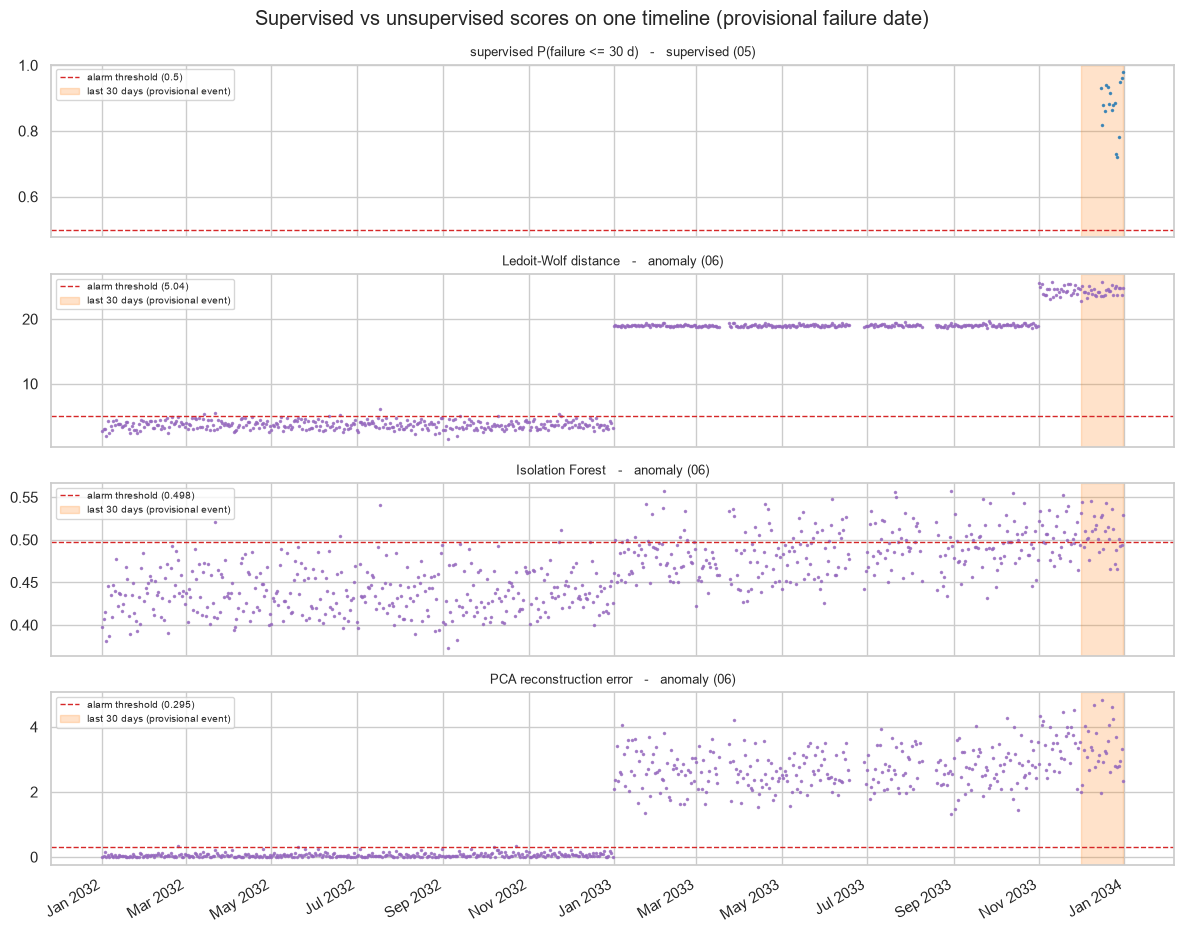

In [7]:
h_start = FAILURE_DATE - pd.Timedelta(days=MAIN_H)
panels = [
    (f'supervised P(failure <= {MAIN_H} d)', THRESHOLD, 'supervised (05)', 'tab:blue'),
    ('Ledoit-Wolf distance', float(anom_thresholds['Ledoit-Wolf distance']), 'anomaly (06)', 'tab:purple'),
    ('Isolation Forest', float(anom_thresholds['Isolation Forest']), 'anomaly (06)', 'tab:purple'),
    ('PCA reconstruction error', float(anom_thresholds['PCA reconstruction error']), 'anomaly (06)', 'tab:purple'),
]

fig, axes = plt.subplots(len(panels), 1, figsize=(12, 9.5), sharex=True)
for ax, (col, thr, group, color) in zip(axes, panels):
    s = streams[col]
    ax.plot(s.index, s.values, '.', ms=3, color=color, alpha=0.75)
    ax.axhline(thr, color='tab:red', ls='--', lw=1, label=f'alarm threshold ({thr:.3g})')
    ax.axvspan(h_start, FAILURE_DATE, color='tab:orange', alpha=0.22,
               label=f'last {MAIN_H} days (provisional event)')
    ax.set_title(f'{col}   -   {group}', fontsize=9)
    ax.legend(loc='upper left', fontsize=7)

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(axes[-1].get_xticklabels(), rotation=30, ha='right')
fig.suptitle('Supervised vs unsupervised scores on one timeline (provisional failure date)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_07_plot_01.png', dpi=130, bbox_inches='tight')
plt.show()


## Analysis step 7

Measure agreement between supervised probabilities and anomaly scores using rank correlation and smoothed trends. Agreement means the methods rank dates similarly, not that they identify the same cause.

In [8]:
agree = []
for name in anom.columns:
    both = streams[[f'supervised P(failure <= {MAIN_H} d)', name]].dropna()
    rho, p = spearmanr(both.iloc[:, 0], both.iloc[:, 1])
    smooth = both.rolling(14, min_periods=7).mean().dropna()
    rho_s, _ = spearmanr(smooth.iloc[:, 0], smooth.iloc[:, 1])
    agree.append({'anomaly_model': name, 'overlap_days': len(both),
                  'spearman_rho': rho, 'p_value': p, 'spearman_rho_14d': rho_s})

agreement = pd.DataFrame(agree).set_index('anomaly_model')
display(agreement.round(3))
agreement.to_csv(TABLE_DIR / '07_score_agreement.csv')
print('saved:', TABLE_DIR / '07_score_agreement.csv')


,overlap_days,spearman_rho,p_value,spearman_rho_14d
anomaly_model,,,,
Ledoit-Wolf distance,17,-0.125,0.633,-0.673
Isolation Forest,17,0.225,0.384,0.800
PCA reconstruction error,17,-0.297,0.248,-0.036


saved: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables\07_score_agreement.csv


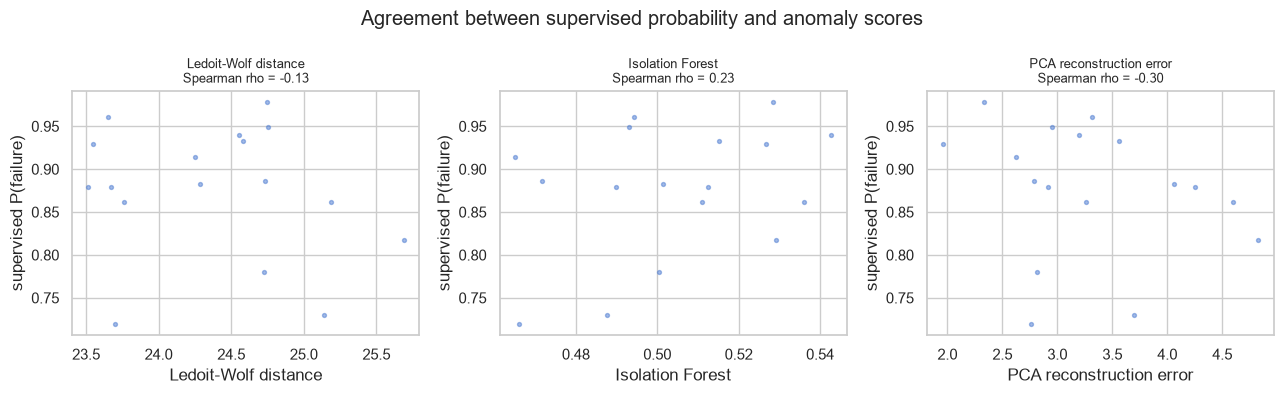

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, anom.columns):
    both = streams[[f'supervised P(failure <= {MAIN_H} d)', name]].dropna()
    ax.scatter(both.iloc[:, 1], both.iloc[:, 0], s=8, alpha=0.5, color='#4878D0')
    ax.set_xlabel(name)
    ax.set_ylabel('supervised P(failure)')
    ax.set_title(f'{name}\nSpearman rho = {agreement.loc[name, "spearman_rho"]:.2f}', fontsize=9)

fig.suptitle('Agreement between supervised probability and anomaly scores')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_07_plot_02.png', dpi=130, bbox_inches='tight')
plt.show()


## Analysis step 8

Compare score relationships in scatter plots. Clusters or trends show whether high anomaly scores tend to coincide with high supervised risk estimates.

calibration_sustained_days  \
model                    quantile                               
Ledoit-Wolf distance     0.950                              0   
                         0.975                              0   
                         0.990                              0   
Isolation Forest         0.950                              0   
                         0.975                              0   
                         0.990                              0   
PCA reconstruction error 0.950                              0   
                         0.975                              0   
                         0.990                              0   

                                   calibration_sustained_episodes  \
model                    quantile                                   
Ledoit-Wolf distance     0.950                                  0   
                         0.975                                  0   
                         0.990                                  0   
Isolation Forest         0.950                                  0   
                         0.975                                  0   
                         0.990                                  0   
PCA reconstruction error 0.950                                  0   
                         0.975                                  0   
                         0.990                                  0   

                                  first_sustained_alarm_2033  \
model                    quantile                              
Ledoit-Wolf distance     0.950                    2033-01-05   
                         0.975                    2033-01-05   
                         0.990                    2033-01-05   
Isolation Forest         0.950                    2033-01-11   
                         0.975                    2033-06-16   
                         0.990                    2033-06-16   
PCA reconstruction error 0.950                    2033-01-05   
                         0.975                    2033-01-05   
                         0.990                    2033-01-05   

                                   eligible_2033_days  sustained_2033_days  \
model                    quantile                                            
Ledoit-Wolf distance     0.950                    340                  324   
                         0.975                    340                  324   
                         0.990                    340                  324   
Isolation Forest         0.950                    340                  136   
                         0.975                    340                   59   
                         0.990                    340                   31   
PCA reconstruction error 0.950                    340                  324   
                         0.975                    340                  324   
                         0.990                    340                  324   

                                   share_2033_sustained  \
model                    quantile                         
Ledoit-Wolf distance     0.950                    0.953   
                         0.975                    0.953   
                         0.990                    0.953   
Isolation Forest         0.950                    0.400   
                         0.975                    0.174   
                         0.990                    0.091   
PCA reconstruction error 0.950                    0.953   
                         0.975                    0.953   
                         0.990                    0.953   

                                   sustained_2033_episodes  continuous_alarm  
model                    quantile                                             
Ledoit-Wolf distance     0.950                           4              True  
                         0.975                           4              True  
                         0.99

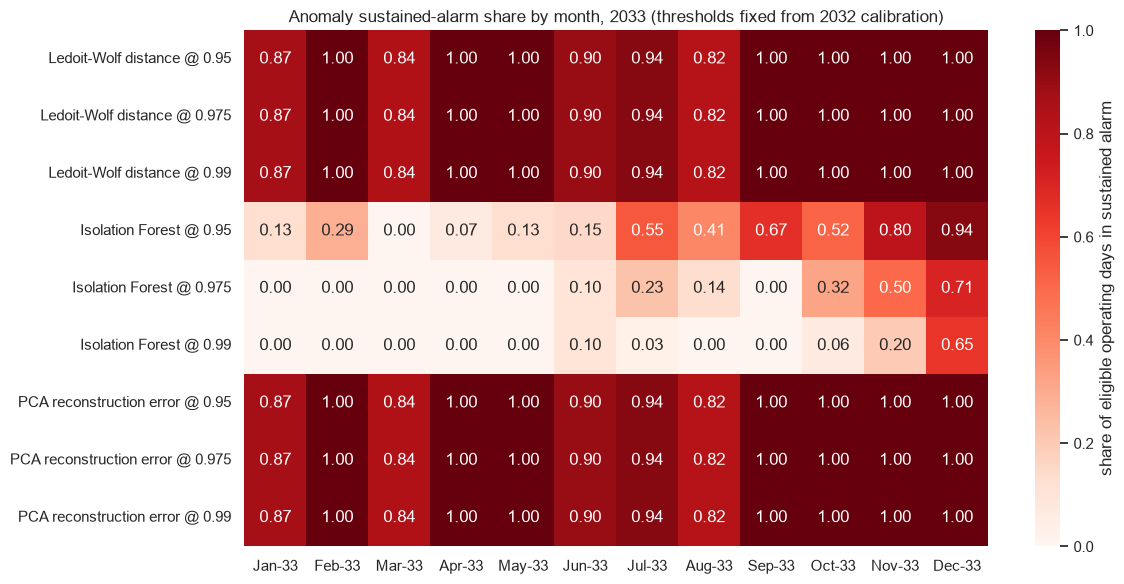

Diagnosed 9 detector/quantile variants with thresholds fixed by notebook 06.
6 sustain alarms on >50% of eligible 2033 days; worst is ('Ledoit-Wolf distance', np.float64(0.95)) at 95%, best is ('Isolation Forest', np.float64(0.99)) at 9%.
No thresholds were retuned and no model was selected on lead time.


In [10]:
cal_end = cal_mask.index[cal_mask][-1]
evaluation_start = cal_end + pd.Timedelta(days=1)
thr = anom_cal.set_index(['model', 'calibration_quantile'])['threshold']

def sustained_mask(raw_alarm, segment_id, window=SUSTAIN_WINDOW, count=SUSTAIN_COUNT):
    out = pd.Series(False, index=raw_alarm.index)
    for sid in segment_id.dropna().unique():
        idx = segment_id.index[segment_id.eq(sid)]
        s = raw_alarm.reindex(idx).fillna(False).astype(int)
        out.loc[idx] = (s.rolling(window, min_periods=window).sum() >= count).to_numpy()
    return out

def episode_starts(sust, segment_id):
    eps = pd.Series(False, index=sust.index)
    for sid in segment_id.dropna().unique():
        idx = segment_id.index[segment_id.eq(sid)]
        seg = sust.loc[idx]
        eps.loc[idx] = seg & ~seg.shift(1, fill_value=False)
    return eps

months = pd.period_range('2033-01-01', '2033-12-01', freq='M')
y25 = valid & (clean.index.year == 2033)
eligible_2033 = int(y25.sum())
sust_cache = {}

rows = []
for (m, q), th in thr.items():
    raw = (anom[m] > th) & valid
    sust = sustained_mask(raw, state['segment_id'])
    eps = episode_starts(sust, state['segment_id'])
    sust_cache[(m, q)] = sust
    monthly = []
    for p in months:
        msk = (clean.index.to_period('M') == p) & valid
        elig = int(msk.sum())
        days = int((sust & msk).sum())
        monthly.append(f"{p.strftime('%b')}:{days}/{elig}" if elig else f"{p.strftime('%b')}:n/a")
    first_2033 = sust.index[sust & (sust.index >= evaluation_start)]
    rows.append({
        'model': m, 'quantile': q,
        'calibration_sustained_days': int((sust & cal_mask).sum()),
        'calibration_sustained_episodes': int((eps & cal_mask).sum()),
        'first_sustained_alarm_2033': first_2033[0].date() if len(first_2033) else None,
        'eligible_2033_days': eligible_2033,
        'sustained_2033_days': int((sust & y25).sum()),
        'share_2033_sustained': float((sust & y25).sum()) / eligible_2033,
        'sustained_2033_episodes': int((eps & y25).sum()),
        'monthly_sustained_days_2033': ' | '.join(monthly),
        'continuous_alarm': bool(((sust & y25).sum()) / eligible_2033 > 0.5),
    })

diag = pd.DataFrame(rows).set_index(['model', 'quantile'])
display(diag[[c for c in diag.columns if c != 'monthly_sustained_days_2033']].round(3))
diag.to_csv(TABLE_DIR / '07_anomaly_false_alarm_diagnosis.csv')

mat = pd.DataFrame(index=months)
for (m, q), th in thr.items():
    sust = sust_cache[(m, q)]
    vals = []
    for p in months:
        msk = (clean.index.to_period('M') == p) & valid
        elig = int(msk.sum())
        vals.append(int((sust & msk).sum()) / elig if elig else np.nan)
    mat[f'{m} @ {max(0.95, round(q, 3)):g}'] = vals
mat.index = [p.strftime('%b-%y') for p in months]
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(mat.T, cmap='Reds', vmin=0, vmax=1, annot=True, fmt='.2f', ax=ax,
            cbar_kws={'label': 'share of eligible operating days in sustained alarm'})
ax.set_title('Anomaly sustained-alarm share by month, 2033 (thresholds fixed from 2032 calibration)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_07_plot_03.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'Diagnosed {len(diag)} detector/quantile variants with thresholds fixed by notebook 06.')
print(f'{int(diag["continuous_alarm"].sum())} sustain alarms on >50% of eligible 2033 days; '
      f"worst is {diag['share_2033_sustained'].idxmax()} at {diag['share_2033_sustained'].max():.0%}, "
      f"best is {diag['share_2033_sustained'].idxmin()} at {diag['share_2033_sustained'].min():.0%}.")
print('No thresholds were retuned and no model was selected on lead time.')

## Analysis step 9

Evaluate anomaly thresholds and sustained-alert rules on the post-calibration period. The resulting event table shows when alerts start and how they overlap the reference window.

In [11]:
bundle = joblib.load(MODEL_DIR / '05_logreg_early_warning.joblib')
print('bundle keys:', list(bundle.keys()))
print('horizon:', bundle['horizon'], '| threshold:', bundle['threshold'], '| sustain_k:', bundle['sustain_k'])
assert 'sensor_scaler' in bundle, 'bundle missing sensor_scaler - rerun notebook 05 first'

WINDOWS = cfg['windows']
SENSOR_SCALER = bundle['sensor_scaler']
SCALE_COLS = list(SENSOR_SCALER['columns'])
assert SCALE_COLS == list(SENSOR_SCALER['scaler'].feature_names_in_)
print('sensor scaler: %d columns, fit on %d healthy baseline rows (year %d)' % (
    len(SCALE_COLS), SENSOR_SCALER['n_baseline_rows'], SENSOR_SCALER['baseline_year']))

def preprocess_sensors(raw_window):
    # Raw, cleaned sensor values -> the scaled window notebook 03 built.
    # signal enters the model as channel_099_log; every column is scaled by the
    # RobustScaler fit once on the 2032 healthy baseline (never on future data).
    raw = raw_window.copy()
    if 'channel_099_log' not in raw.columns:
        if 'channel_099' not in raw.columns:
            raise KeyError('raw window needs the asset sensor columns incl. channel_099')
        raw['channel_099_log'] = np.log1p(raw['channel_099'].clip(lower=0))
    X = raw.reindex(columns=SCALE_COLS)
    arr = SENSOR_SCALER['scaler'].transform(X)
    return pd.DataFrame(arr, columns=SCALE_COLS, index=raw.index)

def rolling_slope(x):
    ok = ~np.isnan(x)
    if ok.sum() < 7:
        return np.nan
    t = np.arange(len(x))[ok]
    return np.polyfit(t, x[ok], 1)[0]

def build_features(sc, seg):
    seg = pd.Series(seg)
    parts = []
    for sid in seg.dropna().unique():
        mask = (seg == sid).fillna(False).to_numpy(dtype=bool)
        block = sc.loc[mask, CORE]
        out = {}
        for c in CORE:
            s = block[c]
            for w in WINDOWS:
                out[f'{c}__mean{w}'] = s.rolling(w, min_periods=max(3, w // 2)).mean()
            out[f'{c}__std14'] = s.rolling(14, min_periods=7).std()
            out[f'{c}__slope14'] = s.rolling(14, min_periods=7).apply(rolling_slope, raw=True)
            out[f'{c}__diff1'] = s.diff()
        parts.append(pd.DataFrame(out, index=block.index))
    return pd.concat(parts).sort_index().reindex(sc.index)

def compute_features(scaled_window, seg, bundle=bundle):
    # All model features, same definitions and order as notebooks 04-05.
    feats = build_features(scaled_window, seg)
    m7 = feats[[f'{c}__mean7' for c in CORE]]
    feats['health_abs7'] = m7.abs().mean(axis=1, skipna=False)
    feats['health_max7'] = m7.abs().max(axis=1, skipna=False)
    feats['mahal7'] = np.nan
    mb = bundle['mahal_baseline']
    ok = m7.notna().all(axis=1).to_numpy()
    feats.loc[ok, 'mahal7'] = np.sqrt(mb['estimator'].mahalanobis(
        m7.loc[ok, mb['mean7_columns']].to_numpy(dtype=float)))
    return feats.reindex(columns=bundle['features'])

def score_new(raw_window, seg, bundle=bundle):
    # Score an unscaled, cleaned window: ship scaler -> features -> gate -> probability.
    scaled_window = preprocess_sensors(raw_window)
    Xnew = compute_features(scaled_window, seg)
    ready = Xnew.notna().all(axis=1).to_numpy()
    proba = pd.Series(np.nan, index=Xnew.index)
    proba.iloc[np.where(ready)[0]] = bundle['pipeline'].predict_proba(Xnew[ready])[:, 1]
    alarm = (proba >= bundle['threshold']).fillna(False)
    return pd.DataFrame({'probability': proba, 'alarm': alarm})

# ---- Test 1: preprocessing reproduces channel_scaled.csv exactly ----
scaled_ref = pd.read_csv(INTERIM / 'channel_scaled.csv', index_col=0, parse_dates=True)
repro = preprocess_sensors(clean[SCALE_COLS]).reindex(columns=scaled_ref.columns)
nan_same = (np.isnan(repro.to_numpy()) == np.isnan(scaled_ref.to_numpy())).all()
fin = ~np.isnan(scaled_ref.to_numpy())
scale_parity = bool(np.allclose(repro.to_numpy(dtype=float)[fin], scaled_ref.to_numpy(dtype=float)[fin], atol=1e-9))
print(f'test 1 preprocess == channel_scaled.csv: NaN pattern {nan_same}, values {scale_parity}')
assert nan_same and scale_parity

# ---- Test 2: raw-input path reproduces all stored features, in training order ----
scaled_win = preprocess_sensors(clean[SCALE_COLS])
rebuilt_all = compute_features(scaled_win, table['segment_id'])
stored = table[list(bundle['features'])]
parity_mask = stored.notna().all(axis=1) & rebuilt_all.notna().all(axis=1)
signalff = (stored.loc[parity_mask].to_numpy(dtype=float)
         - rebuilt_all.loc[parity_mask].to_numpy(dtype=float))
max_abs = float(np.abs(signalff).max())
parity = bool(np.allclose(stored.loc[parity_mask].to_numpy(dtype=float),
                          rebuilt_all.loc[parity_mask].to_numpy(dtype=float), atol=1e-8))
print(f'test 2 raw-input parity across all {len(bundle["features"])} features on '
      f'{int(parity_mask.sum())} rows: {parity} (max abs diff {max_abs:.2e})')
assert parity and (stored.columns == rebuilt_all.columns).all()

# ---- Test 3: representative rows get sensible scores ----
usable = table['usable'].astype(bool)
candidates = {
    'healthy 2032 (baseline)': clean.index[usable & (clean.index.year == 2032)][0],
    'mid-2033 (drift)': clean.index[usable & (clean.index.year == 2033)
                                    & (clean.index < FAILURE_DATE - pd.Timedelta(days=60))][0],
    'late 2033 (pre-failure)': table.index[table['label_valid'].astype(bool)][-1],
    'restart day (2033)': clean.index[state['is_restart'] & (clean.index.year == 2033)][0],
    'shutdown day (2033)': clean.index[state['is_shutdown'] & (clean.index.year == 2033)][0],
}
scores_all = score_new(clean[SCALE_COLS], table['segment_id'])
sel = scores_all.reindex(pd.DatetimeIndex(list(candidates.values())))
sel.index = list(candidates.keys())
display(sel.round(3))
hv = sel.loc['healthy 2032 (baseline)', 'alarm']
pv = sel.loc['late 2033 (pre-failure)', 'alarm']
assert not bool(hv), 'healthy 2032 row should not alarm'
assert bool(pv), 'pre-failure row should alarm'
print('test 3 passed: healthy 2032 does not alarm, pre-failure 2033 does; '
      'restart and shutdown days return NaN instead of a spurious score.')

# ---- Test 4: missing-value handling follows the evaluation gating ----
base_day = clean.index[usable & (clean.index.year == 2032)][0]
ref = scores_all.loc[base_day]
clean_core = clean.copy(); clean_core.loc[base_day, 'channel_098'] = np.nan
s_core = score_new(clean_core[SCALE_COLS], table['segment_id']).loc[base_day]
clean_nc = clean.copy(); clean_nc.loc[base_day, 'channel_005'] = np.nan
s_nc = score_new(clean_nc[SCALE_COLS], table['segment_id']).loc[base_day]
first_days = table.index[table['day_in_segment'].fillna(-1) == 0]
s_first = scores_all.loc[first_days]
print(f'test 4 core sensor missing  -> probability={s_core["probability"]:.3f}, alarm={s_core["alarm"]}')
print(f'test 4 non-core sensor missing -> probability={s_nc["probability"]:.6f} (reference {ref["probability"]:.6f})')
print(f'test 4 insufficient history (segment-start rows={len(first_days)}) -> all NaN={s_first["probability"].isna().all()}')
assert pd.isna(s_core['probability']) and not bool(s_core['alarm'])
assert abs(s_nc['probability'] - ref['probability']) < 1e-9
assert s_first['probability'].isna().all()
print('test 4 passed: missing core sensor or insufficient history -> not scored (NaN), never a bogus alarm.')

demo = scores_all.loc[table.index[usable]].tail(45)
display(demo.round(3))
print('days flagged in the last 45 usable days:', int(demo['alarm'].sum()))

bundle keys: ['pipeline', 'features', 'horizon', 'threshold', 'sustain_k', 'mahal_baseline', 'sensor_scaler', 'note']
horizon: 30 | threshold: 0.5 | sustain_k: 3
sensor scaler: 100 columns, fit on 366 healthy baseline rows (year 2032)


test 1 preprocess == channel_scaled.csv: NaN pattern True, values True


test 2 raw-input parity across all 87 features on 657 rows: True (max abs diff 1.08e-12)


,probability,alarm
healthy 2032 (baseline),0.000,False
mid-2033 (drift),0.000,False
late 2033 (pre-failure),0.995,True
restart day (2033),NaN,False
shutdown day (2033),NaN,False


test 3 passed: healthy 2032 does not alarm, pre-failure 2033 does; restart and shutdown days return NaN instead of a spurious score.


test 4 core sensor missing  -> probability=nan, alarm=False
test 4 non-core sensor missing -> probability=0.000318 (reference 0.000318)
test 4 insufficient history (segment-start rows=4) -> all NaN=True
test 4 passed: missing core sensor or insufficient history -> not scored (NaN), never a bogus alarm.


,probability,alarm
timestamp,,
2033-11-17,0.214,False
2033-11-18,0.130,False
2033-11-19,0.156,False
2033-11-20,0.141,False
2033-11-21,0.160,False
2033-11-22,0.114,False
2033-11-23,0.169,False
2033-11-24,0.126,False
2033-11-25,0.176,False


days flagged in the last 45 usable days: 33


## Analysis step 10

Load the exported model bundle and check that it contains the preprocessing and prediction metadata required for reuse. These checks support consistent future scoring.

In [12]:
print('SUMMARY (provisional single-event evaluation)')
print('-' * 64)
print(f'Supervised (05): {len(sup_timing)} models, longest lead '
      f'{sup_timing["lead_days_to_failure_date"].max():.0f} days before the configured date.')
print(f'Anomaly (06): {len(anom_timing)} model/quantile pairs, longest lead '
      f'{anom_timing["lead_days_to_configured_date"].max():.0f} days.')
print()
print('Anomaly false alarms (held-out 2032 healthy calibration block):')
for _, r in leaderboard[leaderboard['approach'] == 'anomaly (06)'].iterrows():
    share = r['sustained_alarm_share_2033']
    share_txt = 'n/a' if pd.isna(share) else f'{share * 100:.0f}%'
    print(f"  - {r['model']} @ {r['alarm_setting']}: "
          f"{r['false_alarm_days_per_month']:.1f} sustained / "
          f"{r['false_alarm_days_per_month_raw']:.1f} raw days per month on healthy days; "
          f"{share_txt} of eligible 2033 days in sustained alarm")
print()
print('Anomaly false-alarm diagnosis (section 7.' + 'x, thresholds fixed from 2032 calibration, not retuned):')
for (m, q), r in diag.iterrows():
    print(f"  - {m} @ {q:g}: calibration {r['calibration_sustained_days']:.0f} sustained days, "
          f"{r['share_2033_sustained'] * 100:.0f}% of eligible 2033 days sustained, "
          f"continuous={r['continuous_alarm']}")
print()
print('Agreement (Spearman rho) between supervised probability and anomaly scores, '
      'overlap days in parentheses:')
for name, r in agreement['spearman_rho'].items():
    print(f'  - {name}: {r:.2f} ({agreement.loc[name, "overlap_days"]:.0f} days)')
print('Saved:')
for p in [TABLE_DIR / '07_comparison_leaderboard.csv', TABLE_DIR / '07_score_agreement.csv',
          TABLE_DIR / '07_anomaly_false_alarm_diagnosis.csv',
          FIG_DIR / 'notebook_07_plot_04.png', FIG_DIR / 'notebook_07_plot_05.png',
          FIG_DIR / 'notebook_07_plot_06.png']:
    print('  ', p)

SUMMARY (provisional single-event evaluation)
----------------------------------------------------------------
Supervised (05): 2 models, longest lead 14 days before the configured date.
Anomaly (06): 9 model/quantile pairs, longest lead 360 days.

Anomaly false alarms (held-out 2032 healthy calibration block):
  - Isolation Forest @ quantile 0.95: 0.0 sustained / 1.7 raw days per month on healthy days; 40% of eligible 2033 days in sustained alarm
  - Isolation Forest @ quantile 0.975: 0.0 sustained / 0.8 raw days per month on healthy days; 17% of eligible 2033 days in sustained alarm
  - Isolation Forest @ quantile 0.99: 0.0 sustained / 0.6 raw days per month on healthy days; 9% of eligible 2033 days in sustained alarm
  - Ledoit-Wolf distance @ quantile 0.95: 0.0 sustained / 1.7 raw days per month on healthy days; 95% of eligible 2033 days in sustained alarm
  - Ledoit-Wolf distance @ quantile 0.975: 0.0 sustained / 0.8 raw days per month on healthy days; 95% of eligible 2033 days in